# QPINN — training, evaluation, and plotting
End-to-end walkthrough using the new pipeline (`train.py`, `eval.py`, `plotter.py`).

## 0 - Setup

In [13]:
%reload_ext autoreload
import torch
import numpy as np
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

import sys
import os

# Adds the parent directory (root of your project) to the python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.models import MerlinHeatQPINN, MerlinTunableSimple
from src.pde import WaveEquation          # swap for BurgersPDE / WavePDE as needed
from src.loss import total_loss
from src.train   import train
from src.eval    import evaluate
from src.plotter import plot_training_history, plot_solution_comparison
from src.utils import hilbert_space_dimension, quantum_outputsize_for_param_match, find_matching_hidden_readout

In [14]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
#device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
dtype  = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

device: cpu  |  dtype: torch.float32


## 1 - Build QPINN model and PDE

In [17]:
# Find matching model parameters between quantum and classical 

FEATURE_SIZES_guess = [4]#[2,4,8,16]
FEATURE_SIZE, HIDDEN_READOUT = find_matching_hidden_readout(feature_sizes=FEATURE_SIZES_guess, ranges=[1,100])

print(FEATURE_SIZE)
print(HIDDEN_READOUT)
#select smallest
FEATURE_SIZE = FEATURE_SIZE[0]
HIDDEN_READOUT = HIDDEN_READOUT[0]
QUANTUM_OUTPUT_SIZE = int(quantum_outputsize_for_param_match(FEATURE_SIZE, HIDDEN_READOUT))


[[  1   1]
 [  1   2]
 [  1   3]
 ...
 [ 98 100]
 [ 99 100]
 [100 100]]
[4]
[4]


In [ ]:
VELOCITY = 0.732423
FREQUENCY = 4.0
used_pde = WaveEquation(c=VELOCITY, freq=FREQUENCY)

In [8]:
# Model
model = MerlinTunableSimple(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, pde=used_pde)
model = model.to(device)

print(f"total_params = {sum(p.numel() for p in model.parameters())}")

total_params = 177


## 2 - Train model

In [9]:
history = train(model = model, pde = used_pde, epochs=800)

Parameters — total: 177  trainable: 177

Training for 800 epochs on cpu  (dtype=torch.float32)
Epoch     1/800 | Loss: 8.6875e+02 | PDE: 8.62e+02 | Cons: 7.09e+01 | IC: 0.00e+00 | BC: 1.22e-13 | Time: 0.1s
Epoch    50/800 | Loss: 7.5801e+02 | PDE: 7.50e+02 | Cons: 8.14e+01 | IC: 0.00e+00 | BC: 1.22e-13 | Time: 2.3s
Epoch   100/800 | Loss: 6.0687e+02 | PDE: 6.01e+02 | Cons: 5.47e+01 | IC: 0.00e+00 | BC: 1.22e-13 | Time: 4.6s
Epoch   150/800 | Loss: 4.2927e+02 | PDE: 4.25e+02 | Cons: 4.41e+01 | IC: 0.00e+00 | BC: 1.22e-13 | Time: 6.9s
Epoch   200/800 | Loss: 3.8743e+02 | PDE: 3.83e+02 | Cons: 4.33e+01 | IC: 0.00e+00 | BC: 1.22e-13 | Time: 9.4s
Epoch   250/800 | Loss: 3.3508e+02 | PDE: 3.31e+02 | Cons: 3.62e+01 | IC: 0.00e+00 | BC: 1.22e-13 | Time: 11.8s
Epoch   300/800 | Loss: 2.8979e+02 | PDE: 2.87e+02 | Cons: 2.88e+01 | IC: 0.00e+00 | BC: 1.22e-13 | Time: 14.1s
Epoch   350/800 | Loss: 2.4680e+02 | PDE: 2.44e+02 | Cons: 2.78e+01 | IC: 0.00e+00 | BC: 1.22e-13 | Time: 16.4s
Epoch   400/80

## 3 - Plot training history

Saved: ../figures/demo/history_0.5_4.0.png


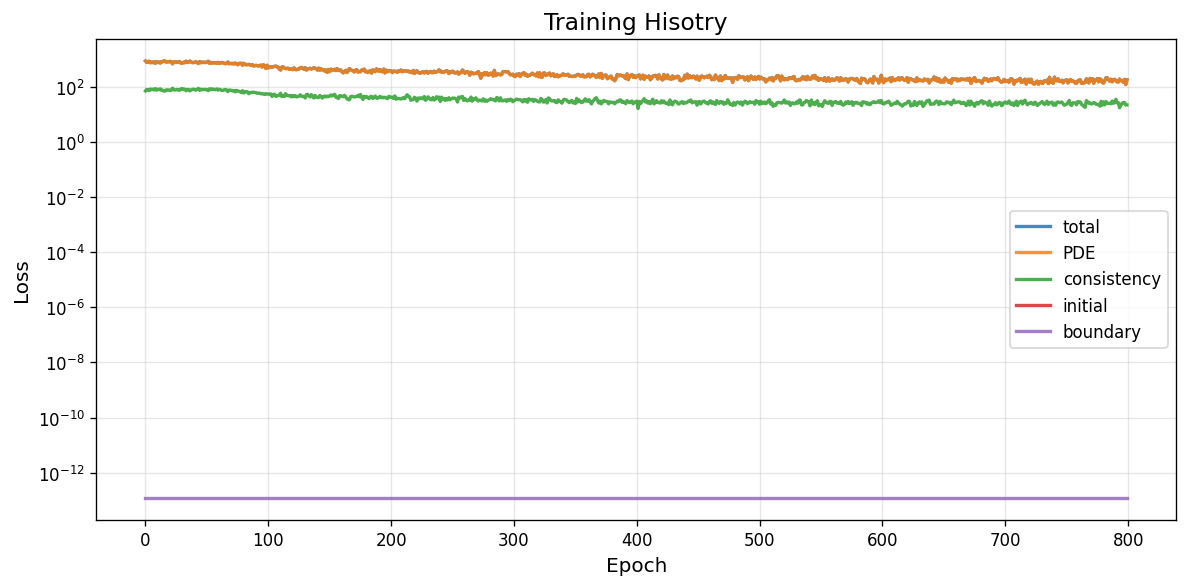

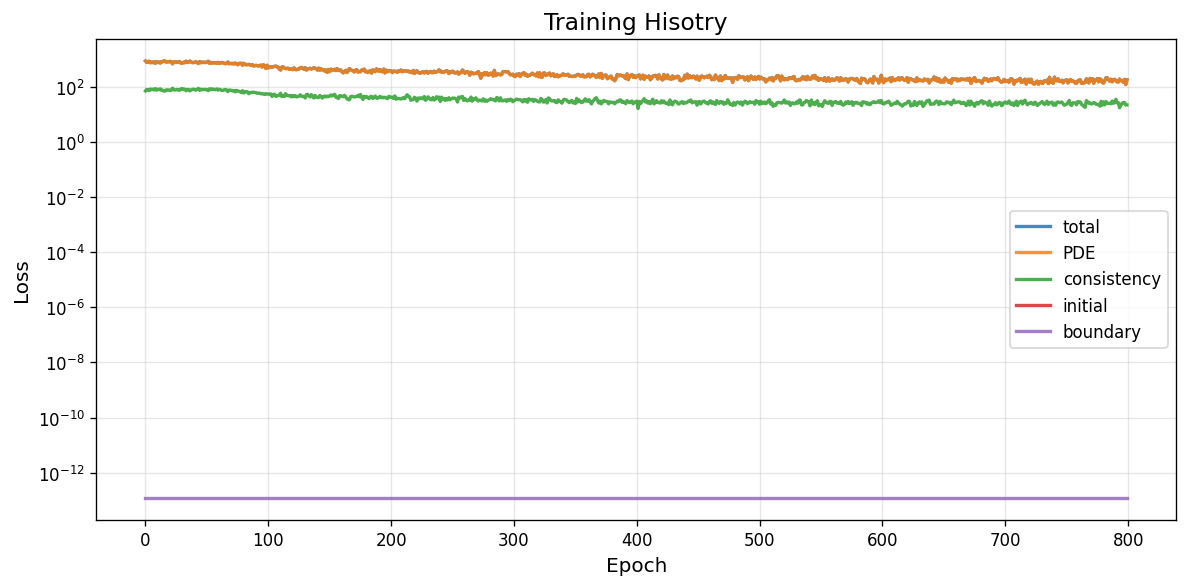

In [10]:
plot_training_history(
    history,
    save_path =f'../figures/demo/history_{VELOCITY}_{FREQUENCY}.png',  # set to None to skip saving
    show      = True,
)

## 7 - Evaluate model over grid

In [11]:
metrics, U_pred, U_true, x_grid, t_grid = evaluate(
    model  = model,
    pde    = used_pde
)
print(metrics)

Evaluating on 60×60 grid …
  Relative L2 : 1.2302e+00
  MAE         : 4.7530e-01
  Max abs err : 1.5170e+00
  RMSE        : 6.1501e-01
{'rel_l2': 1.2301868200302124, 'mae': 0.47529980540275574, 'max_abs_error': 1.5169684886932373, 'rmse': 0.6150078177452087}


## 8 - Plot solution comparison

Saved: ../figures/demo/solution_quant_0.5_4.0.png


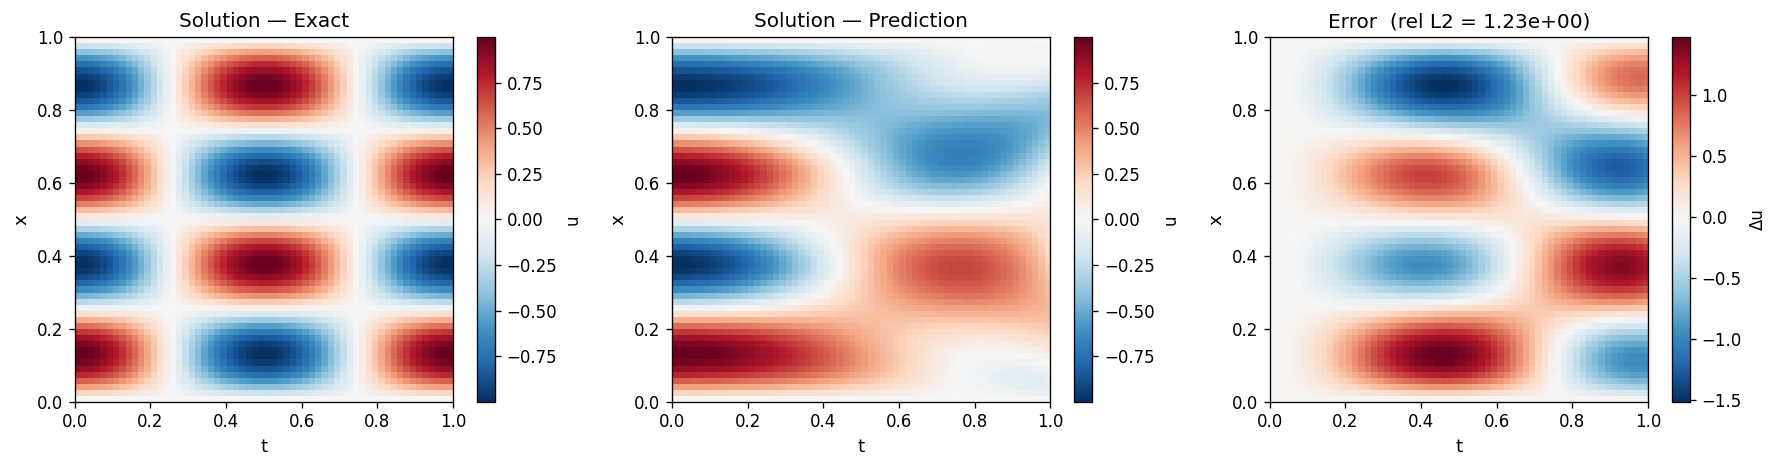

Relative L2 error: 1.2302e+00


In [12]:
fig, rel_l2 = plot_solution_comparison(
    U_pred    = U_pred,
    U_true    = U_true,
    x_grid    = x_grid,
    t_grid    = t_grid,
    save_path =f'../figures/demo/solution_quant_{VELOCITY}_{FREQUENCY}.png',
    show      = True,
)
print(f'Relative L2 error: {rel_l2:.4e}')

## 9 - Repeat process for Classial PINN to compare result

Parameters — total: 310  trainable: 310

Training for 800 epochs on cpu  (dtype=torch.float32)
Epoch     1/800 | Loss: 9.0514e+02 | PDE: 8.98e+02 | Cons: 6.68e+01 | IC: 0.00e+00 | BC: 1.22e-13 | Time: 0.0s
Epoch    50/800 | Loss: 6.8585e+02 | PDE: 6.78e+02 | Cons: 7.55e+01 | IC: 0.00e+00 | BC: 1.22e-13 | Time: 0.2s
Epoch   100/800 | Loss: 8.1037e+02 | PDE: 8.04e+02 | Cons: 6.62e+01 | IC: 0.00e+00 | BC: 1.22e-13 | Time: 0.3s
Epoch   150/800 | Loss: 7.4133e+02 | PDE: 7.36e+02 | Cons: 5.64e+01 | IC: 0.00e+00 | BC: 1.22e-13 | Time: 0.4s
Epoch   200/800 | Loss: 7.0516e+02 | PDE: 6.99e+02 | Cons: 6.26e+01 | IC: 0.00e+00 | BC: 1.22e-13 | Time: 0.6s
Epoch   250/800 | Loss: 8.4110e+02 | PDE: 8.35e+02 | Cons: 6.59e+01 | IC: 0.00e+00 | BC: 1.22e-13 | Time: 0.7s
Epoch   300/800 | Loss: 6.1322e+02 | PDE: 6.07e+02 | Cons: 5.94e+01 | IC: 0.00e+00 | BC: 1.22e-13 | Time: 0.8s
Epoch   350/800 | Loss: 5.1214e+02 | PDE: 5.06e+02 | Cons: 5.82e+01 | IC: 0.00e+00 | BC: 1.22e-13 | Time: 1.0s
Epoch   400/800 |

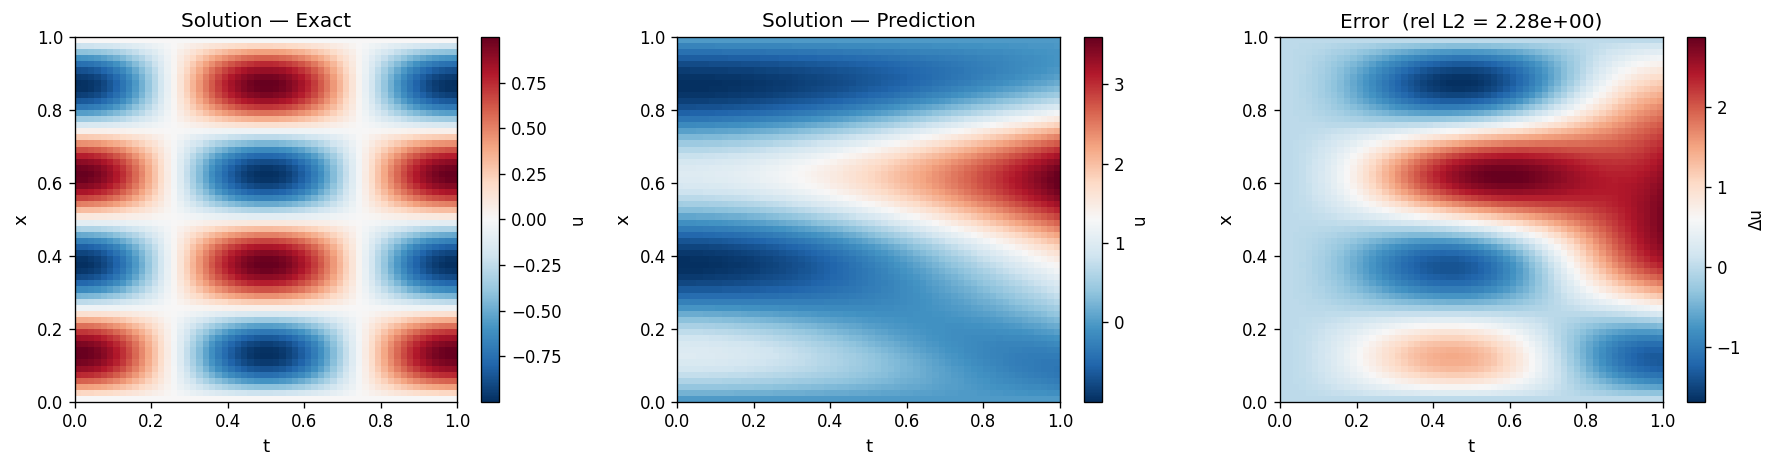

Relative L2 error: 2.2795e+00


In [36]:
from src.models import ClassicalHeatQPINN


classical_model = ClassicalHeatQPINN(feature_size=FEATURE_SIZE, hidden_readout=HIDDEN_READOUT, quantum_output_size=QUANTUM_OUTPUT_SIZE, pde = used_pde)
classical_model = classical_model.to(device)


history = train(model = classical_model, pde = used_pde, loss_fn=total_loss, epochs=800)

metrics, U_pred, U_true, x_grid, t_grid = evaluate(
    model  = classical_model,
    pde    = used_pde,
)

fig, rel_l2 = plot_solution_comparison(
    U_pred    = U_pred,
    U_true    = U_true,
    x_grid    = x_grid,
    t_grid    = t_grid,
    save_path =f'../figures/demo/solution_class_{VELOCITY}_{FREQUENCY}.png',
    show      = True,
)
print(f'Relative L2 error: {rel_l2:.4e}')